# Step 11: neural network, rung M7

This notebook trains a multilayer perceptron on the 50 core features and compares ReLU, tanh and sigmoid activations.

## Setup and input checks

Imports, helpers, paths and the checks on the input files.

In [1]:
import sys, json, time, copy, warnings, contextlib
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, precision_recall_curve, roc_curve
from sklearn.exceptions import ConvergenceWarning

HIDDEN = (64, 32)
NEG_RATIO = 4
BATCH = 512
MAX_EPOCHS = 40
PATIENCE = 5
SEED = 42
SEED_EXTRA = [43, 44, 45]
RUN_CV = True

KNOWN = {
    "train": dict(patients=28235, rows=1085958, pos=19530),
    "val": dict(patients=6050, rows=234037, pos=4183, septic=440, first_row=65, never=5610),
    "test": dict(patients=6051, rows=232215, pos=4203, septic=440, first_row=63, never=5611),
}
TOTAL_ROWS = 1552210
EXPECTED_PARAMS = 5377
FORBIDDEN = ["patient_id", "hospital", "hour", "split", "SepsisLabel"]

sns.set_theme(style="whitegrid")
SEPTIC, CONTROL = "#d1495b", "#2e86ab"
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

SUMMARY, SAVED = [], []
COUNT = {"pass": 0, "fail": 0}
WARN = {"convergence": 0}


def log(text=""):
    tqdm.write(str(text))
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    COUNT["pass" if ok else "fail"] += 1
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail != "" else ""))
    return ok


def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")


@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")


@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")


def save_fig(name):
    plt.tight_layout()
    path = FIG / name
    plt.savefig(path, dpi=150)
    SAVED.append(path)
    plt.show()
    plt.close()


def gate(section, fails_before):
    if COUNT["fail"] > fails_before:
        raise RuntimeError(f"stopping: a check failed in {section} and the later sections depend on it")


def table(df):
    log(df.to_string(index=False))


def find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "dataset").is_dir():
            return p
    raise FileNotFoundError(f"no folder with a 'dataset' directory above {here}")


ROOT = find_root()
PROC = ROOT / "data" / "processed"
RES = ROOT / "results"
TAB = RES / "tables"
FIG = RES / "figures"
SRC = ROOT / "src"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC))
import sepsis_eval as ev

log(f"root: {ROOT}")

root: /Users/harnoorkaur/Downloads/Sepsis_ml


In [2]:
n0 = COUNT["fail"]
with timed("section 1"):
    core = pd.read_parquet(PROC / "core_scaled.parquet")
    flat_keys = pd.read_parquet(PROC / "features_flat.parquet", columns=["patient_id", "hour"])
    splits = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})
    FEATS = [c for c in core.columns if c not in FORBIDDEN]
    N_FEAT = len(FEATS)
    sp = core["split"].astype(str).to_numpy()
    y_all = core["SepsisLabel"].to_numpy(np.float32)

    with guarded("known sizes"):
        expect("total rows", len(core), TOTAL_ROWS)
        for s, k in KNOWN.items():
            m = sp == s
            sub = splits[splits["split"] == s]
            expect(f"{s} rows", int(m.sum()), k["rows"])
            expect(f"{s} positive rows", int(y_all[m].sum()), k["pos"])
            expect(f"{s} patients", len(sub), k["patients"])
            if "septic" in k:
                sept = sub["ever_septic"].astype(int) == 1
                expect(f"{s} septic patients", int(sept.sum()), k["septic"])
                expect(f"{s} first-row septic patients", int((sept & (sub["first_positive_hour"] == 0)).sum()), k["first_row"])
                expect(f"{s} never-septic patients", int((~sept).sum()), k["never"])

    with guarded("alignment with features_flat"):
        same_id = np.array_equal(core["patient_id"].astype(str).to_numpy(), flat_keys["patient_id"].astype(str).to_numpy())
        same_hour = np.array_equal(core["hour"].to_numpy(), flat_keys["hour"].to_numpy())
        check("core_scaled aligned with features_flat on patient_id and hour", len(core) == len(flat_keys) and same_id and same_hour)

    with guarded("feature columns"):
        expect("number of feature columns", N_FEAT, 50)
        check("no forbidden column is a feature", not (set(FEATS) & set(FORBIDDEN)))
        X_all = core[FEATS].to_numpy(np.float32)
        check("features have no NaN or inf", np.isfinite(X_all).all())
gate("section 1", n0)

[PASS] total rows (observed 1552210, expected 1552210)
[PASS] train rows (observed 1085958, expected 1085958)
[PASS] train positive rows (observed 19530, expected 19530)
[PASS] train patients (observed 28235, expected 28235)
[PASS] val rows (observed 234037, expected 234037)
[PASS] val positive rows (observed 4183, expected 4183)
[PASS] val patients (observed 6050, expected 6050)
[PASS] val septic patients (observed 440, expected 440)
[PASS] val first-row septic patients (observed 65, expected 65)
[PASS] val never-septic patients (observed 5610, expected 5610)
[PASS] test rows (observed 232215, expected 232215)
[PASS] test positive rows (observed 4203, expected 4203)
[PASS] test patients (observed 6051, expected 6051)
[PASS] test septic patients (observed 440, expected 440)
[PASS] test first-row septic patients (observed 63, expected 63)
[PASS] test never-septic patients (observed 5611, expected 5611)
[PASS] core_scaled aligned with features_flat on patient_id and hour
[PASS] number of

## Load data

Arrays are float32 and the meta tables keep the row order of the scores.

In [3]:
n0 = COUNT["fail"]
with timed("section 2"):
    pid = core["patient_id"].astype(str).to_numpy()
    hour = core["hour"].to_numpy()
    masks = {s: sp == s for s in ["train", "val", "test"]}
    X_tr, X_va, X_te = (X_all[masks[s]] for s in ["train", "val", "test"])
    y_tr, y_va, y_te = (y_all[masks[s]] for s in ["train", "val", "test"])
    del X_all

    def make_meta(m):
        base = pd.DataFrame({"patient_id": pid[m], "hour": hour[m]})
        return base.merge(splits[["patient_id", "ever_septic", "first_positive_hour"]], on="patient_id", how="left")

    meta_va, meta_te = make_meta(masks["val"]), make_meta(masks["test"])
    check("meta tables match the score rows", len(meta_va) == len(y_va) and len(meta_te) == len(y_te)
          and np.array_equal(meta_va["patient_id"].to_numpy(), pid[masks["val"]])
          and np.array_equal(meta_te["patient_id"].to_numpy(), pid[masks["test"]]))
    ok_meta = all(not m["ever_septic"].isna().any() and not m.loc[m["ever_septic"] == 1, "first_positive_hour"].isna().any()
                  for m in (meta_va, meta_te))
    check("no missing ever_septic, and first_positive_hour known for septic patients", ok_meta)
    shapes = pd.DataFrame({"split": ["train", "val", "test"],
                           "rows": [len(y_tr), len(y_va), len(y_te)],
                           "positive_rows": [int(y_tr.sum()), int(y_va.sum()), int(y_te.sum())],
                           "features": [X_tr.shape[1], X_va.shape[1], X_te.shape[1]]})
    table(shapes)
    sizes = [N_FEAT, *HIDDEN, 1]
    n_params = sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))
    log(f"network parameters for {HIDDEN} with {N_FEAT} inputs: {n_params:,} (expected {EXPECTED_PARAMS:,})")
gate("section 2", n0)

[PASS] meta tables match the score rows
[PASS] no missing ever_septic, and first_positive_hour known for septic patients
split    rows  positive_rows  features
train 1085958          19530        50
  val  234037           4183        50
 test  232215           4203        50
network parameters for (64, 32) with 50 inputs: 5,377 (expected 5,377)
section 2: 0.2 s


## Training function

One epoch is one partial_fit call on all positive rows and a fresh sample of negatives.

In [4]:
def make_model(cfg, seed):
    return MLPClassifier(hidden_layer_sizes=HIDDEN, activation=cfg["activation"], solver="adam", alpha=cfg["alpha"],
                         batch_size=BATCH, learning_rate_init=cfg["learning_rate_init"], random_state=seed)


def one_epoch(model, X, y, pos, neg, rng):
    take = rng.choice(neg, size=min(NEG_RATIO * len(pos), len(neg)), replace=False)
    idx = rng.permutation(np.concatenate([pos, take]))
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        model.partial_fit(X[idx], y[idx].astype(np.int64), classes=np.array([0, 1]))
    WARN["convergence"] += sum(issubclass(i.category, ConvergenceWarning) for i in w)
    return len(pos), len(take)


def val_weights(y):
    n_pos = float(y.sum())
    return np.where(y == 1, 1.0, NEG_RATIO * n_pos / (len(y) - n_pos))


def wloss(y, p, w):
    return log_loss(y.astype(np.int64), p.astype(np.float64), sample_weight=w, labels=[0, 1])


def train_mlp(config, seed, X_tr, y_tr, X_va, y_va, max_epochs, patience):
    model, rng = make_model(config, seed), np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y_tr == 1), np.flatnonzero(y_tr == 0)
    w = val_weights(y_va)
    best_loss, best_epoch, best_model, stopped, rows = np.inf, 0, None, False, []
    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        n_p, n_n = one_epoch(model, X_tr, y_tr, pos, neg, rng)
        p = model.predict_proba(X_va)[:, 1]
        vl, cm = wloss(y_va, p, w), ev.curve_metrics(y_va, p)
        rows.append(dict(epoch=epoch, train_loss=model.loss_, val_weighted_loss=vl, val_auprc=cm["auprc"],
                         val_auroc=cm["auroc"], seconds=time.time() - t0, n_pos=n_p, n_neg=n_n))
        if vl < best_loss:
            best_loss, best_epoch, best_model = vl, epoch, copy.deepcopy(model)
        elif epoch - best_epoch >= patience:
            stopped = True
            break
    return best_model, pd.DataFrame(rows), best_epoch, stopped


def train_fixed(config, seed, X, y, epochs):
    model, rng = make_model(config, seed), np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    for _ in range(epochs):
        one_epoch(model, X, y, pos, neg, rng)
    return model

## Tuning, ReLU against tanh against sigmoid

Twelve configurations are trained with early stopping and ranked by validation AUPRC.

configurations:   8%|▊         | 1/12 [00:01<00:21,  1.98s/it]

relu     alpha=1e-05 lr=0.001 best epoch 6, val AUPRC 0.106 (2 s)


configurations:  17%|█▋        | 2/12 [00:03<00:17,  1.73s/it]

relu     alpha=1e-05 lr=0.003 best epoch 4, val AUPRC 0.104 (2 s)


configurations:  25%|██▌       | 3/12 [00:05<00:16,  1.83s/it]

relu     alpha=0.001 lr=0.001 best epoch 6, val AUPRC 0.108 (2 s)


... (14 outputs left out)

configurations:  92%|█████████▏| 11/12 [00:24<00:03,  3.33s/it]

logistic alpha=0.001 lr=0.001 best epoch 21, val AUPRC 0.113 (5 s)


configurations: 100%|██████████| 12/12 [00:27<00:00,  2.28s/it]


logistic alpha=0.001 lr=0.003 best epoch 8, val AUPRC 0.110 (2 s)
activation alpha learning_rate_init  best_epoch  early_stopped  val_weighted_loss  val_auprc  val_auroc
      relu 1e-05              0.001           6           True              0.386      0.106      0.823
      relu 1e-05              0.003           4           True              0.387      0.104      0.823
      relu 0.001              0.001           6           True              0.386      0.108      0.823
      relu 0.001              0.003           4           True              0.386      0.104      0.824
      tanh 1e-05              0.001           3           True              0.385      0.103      0.821
      tanh 1e-05              0.003           2           True              0.384      0.099      0.824
      tanh 0.001              0.001           3           True              0.385      0.103      0.821
      tanh 0.001              0.003           2           True              0.384      0.099      0.82

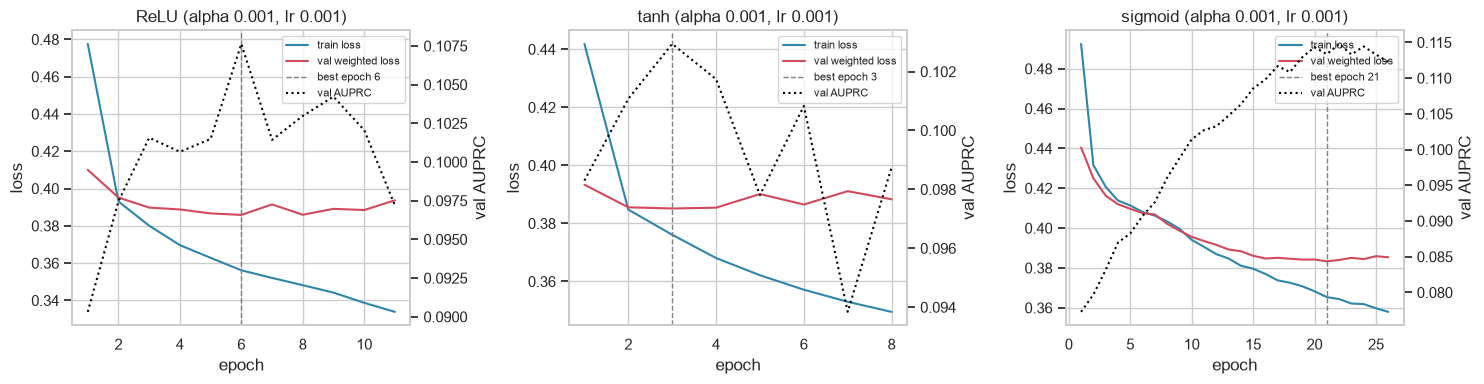

section 4: 27.7 s


In [5]:
n0 = COUNT["fail"]
ACTS = ["relu", "tanh", "logistic"]
GRID = [dict(activation=a, alpha=al, learning_rate_init=lr)
        for a, al, lr in product(ACTS, [1e-5, 1e-3], [1e-3, 3e-3])]
MODELS, EP_BY_CFG, rows = {}, {}, []
with timed("section 4"):
    for i, cfg in enumerate(tqdm(GRID, desc="configurations")):
        t0 = time.time()
        model, ep, be, stopped = train_mlp(cfg, SEED, X_tr, y_tr, X_va, y_va, MAX_EPOCHS, PATIENCE)
        secs = time.time() - t0
        b = ep.loc[ep["epoch"] == be].iloc[0]
        MODELS[i], EP_BY_CFG[i] = model, ep.assign(**cfg)
        rows.append(dict(cfg, best_epoch=be, early_stopped=stopped, val_weighted_loss=b["val_weighted_loss"],
                         val_auprc=b["val_auprc"], val_auroc=b["val_auroc"], train_seconds=secs))
        log(f"{cfg['activation']:8s} alpha={cfg['alpha']:g} lr={cfg['learning_rate_init']:g} "
            f"best epoch {be}, val AUPRC {b['val_auprc']:.3f} ({secs:.0f} s)")

    tuning = pd.DataFrame(rows)
    epoch_log = pd.concat(EP_BY_CFG.values(), ignore_index=True)
    epoch_log = epoch_log[["activation", "alpha", "learning_rate_init", "epoch", "train_loss", "val_weighted_loss",
                           "val_auprc", "val_auroc", "seconds", "n_pos", "n_neg"]]
    tuning.to_csv(TAB / "ann_tuning.csv", index=False)
    epoch_log.to_csv(TAB / "ann_epoch_log.csv", index=False)

    best_idx = tuning.groupby("activation")["val_auprc"].idxmax()
    comp = tuning.loc[best_idx.values].sort_values("val_auprc", ascending=False)
    comp.to_csv(TAB / "ann_activation_comparison.csv", index=False)
    best_i = int(tuning["val_auprc"].idxmax())
    BEST_CFG = GRID[best_i]
    BEST_EPOCH = int(tuning.loc[best_i, "best_epoch"])

    show = tuning.assign(alpha=tuning["alpha"].map("{:g}".format),
                         learning_rate_init=tuning["learning_rate_init"].map("{:g}".format))
    table(show.drop(columns="train_seconds"))
    log("best configuration per activation")
    table(comp.assign(alpha=comp["alpha"].map("{:g}".format),
                      learning_rate_init=comp["learning_rate_init"].map("{:g}".format))[
        ["activation", "alpha", "learning_rate_init", "best_epoch", "val_weighted_loss", "val_auprc", "val_auroc"]])
    log(f"overall best: {BEST_CFG}, best epoch {BEST_EPOCH}, val AUPRC {tuning.loc[best_i, 'val_auprc']:.3f}")

    names = {"relu": "ReLU", "tanh": "tanh", "logistic": "sigmoid"}
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, act in zip(axes, ACTS):
        i = int(best_idx[act])
        ep, be = EP_BY_CFG[i], int(tuning.loc[i, "best_epoch"])
        ax.plot(ep["epoch"], ep["train_loss"], color=CONTROL, label="train loss")
        ax.plot(ep["epoch"], ep["val_weighted_loss"], color=SEPTIC, label="val weighted loss")
        ax.axvline(be, color="grey", ls="--", lw=1, label=f"best epoch {be}")
        ax.set_xlabel("epoch")
        ax.set_ylabel("loss")
        ax.set_title(f"{names[act]} (alpha {GRID[i]['alpha']:g}, lr {GRID[i]['learning_rate_init']:g})")
        ax2 = ax.twinx()
        ax2.plot(ep["epoch"], ep["val_auprc"], color="black", ls=":", label="val AUPRC")
        ax2.set_ylabel("val AUPRC")
        ax2.grid(False)
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
    save_fig("fig11_learning_curves.png")

## Seed stability

The best configuration is retrained with three more seeds, scored on validation only.

In [6]:
with timed("section 5"):
    r0 = tuning.loc[best_i]
    seed_rows = [dict(seed=SEED, best_epoch=int(r0["best_epoch"]), val_auroc=r0["val_auroc"], val_auprc=r0["val_auprc"])]
    for sd in tqdm(SEED_EXTRA, desc="seeds"):
        _, ep, be, _ = train_mlp(BEST_CFG, sd, X_tr, y_tr, X_va, y_va, MAX_EPOCHS, PATIENCE)
        b = ep.loc[ep["epoch"] == be].iloc[0]
        seed_rows.append(dict(seed=sd, best_epoch=be, val_auroc=b["val_auroc"], val_auprc=b["val_auprc"]))
    seeds = pd.DataFrame(seed_rows)
    seeds.to_csv(TAB / "ann_seed_stability.csv", index=False)
    table(seeds)
    log(f"val AUROC mean {seeds['val_auroc'].mean():.3f}, std {seeds['val_auroc'].std():.3f}")
    log(f"val AUPRC mean {seeds['val_auprc'].mean():.3f}, std {seeds['val_auprc'].std():.3f}")
    FINAL = MODELS[best_i]
    log("the ladder uses the seed 42 model")

seeds: 100%|██████████| 3/3 [00:14<00:00,  4.78s/it]

 seed  best_epoch  val_auroc  val_auprc
   42          21      0.824      0.113
   43          20      0.827      0.107
   44          19      0.824      0.111
   45          22      0.824      0.110
val AUROC mean 0.825, std 0.001
val AUPRC mean 0.111, std 0.003
the ladder uses the seed 42 model
section 5: 14.3 s


## Threshold and evaluation of M7_mlp

The threshold is chosen on validation and saved before the test rows are scored.

threshold chosen on val (best F2): 0.4453
wrote /Users/harnoorkaur/Downloads/Sepsis_ml/data/processed/thresholds_m7.json
note: val metrics at a val-tuned threshold are optimistic
model        M7_mlp
n_features       50
threshold     0.445
sensitivity   0.416
specificity   0.932
precision     0.100
f1            0.161
f2            0.255
accuracy      0.923
alert_rate    0.074
auroc         0.824
auprc         0.113
n_early                                      375.000
share_alerted_by_first_label                   0.552
share_alerted_any                              0.707
median_lead_h                                 37.000
median_timing_all_alerted_h                   25.000
n_first_row                                   65.000
share_alerted_any_first_row                    0.369
n_nonseptic                                 5610.000
share_nonseptic_ever_alerted                   0.154
false_alert_episodes_per_100_patient_days     22.703


sweep alert metrics: 100%|██████████| 15/15 [00:00<00:00, 16.56it/s]


 threshold  sensitivity  specificity  precision    f1    f2  share_alerted_by_first_label  false_alert_episodes_per_100_patient_days
     0.012        0.995        0.051      0.019 0.037 0.087                         1.000                                    410.206
     0.019        0.989        0.116      0.020 0.039 0.092                         1.000                                    386.152
     0.027        0.981        0.181      0.021 0.042 0.098                         1.000                                    360.863
     0.037        0.972        0.247      0.023 0.045 0.105                         1.000                                    335.158
     0.049        0.962        0.312      0.025 0.048 0.112                         1.000                                    309.661
     0.062        0.947        0.377      0.027 0.052 0.121                         1.000                                    284.868
     0.076        0.930        0.442      0.029 0.057 0.131          

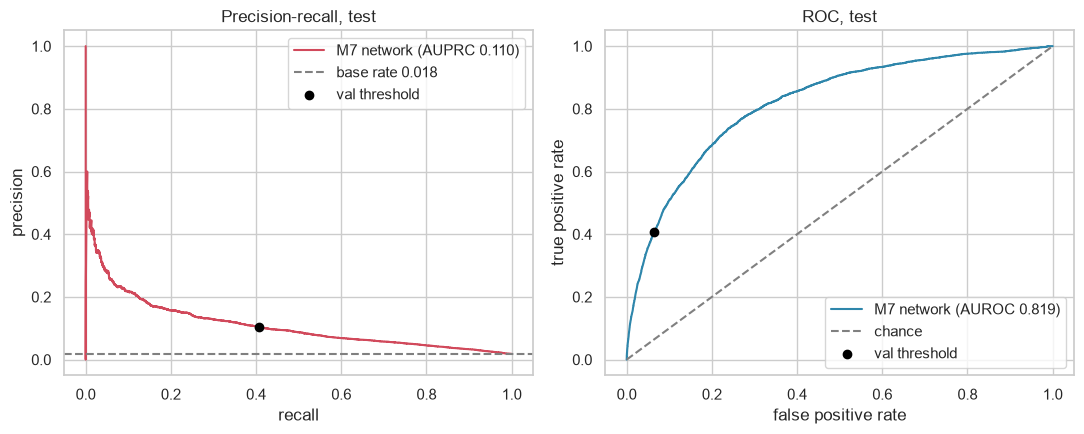

[PASS] parameter count (observed 5377, expected 5377)
[PASS] positive rows in train (observed 19530, expected 19530)
[PASS] every epoch used all positive rows and NEG_RATIO times as many negatives (148 epochs checked)
[PASS] val scores finite and of the right length
[PASS] test scores finite and of the right length
[PASS] thresholds file written before test scoring
[PASS] val early + first-row septic patients (observed 440, expected 440)
[PASS] val first-row septic patients (observed 65, expected 65)
[PASS] val never-septic patients (observed 5610, expected 5610)
[PASS] test early + first-row septic patients (observed 440, expected 440)
[PASS] test first-row septic patients (observed 63, expected 63)
[PASS] test never-septic patients (observed 5611, expected 5611)
[PASS] val confusion matrix sums to the number of rows (observed 234037, expected 234037)
[PASS] test confusion matrix sums to the number of rows (observed 232215, expected 232215)
[PASS] no AUROC above 0.95 (val 0.824, test 

In [7]:
n0 = COUNT["fail"]
THR_PATH = PROC / "thresholds_m7.json"
CONF = ["tp", "fp", "tn", "fn"]


def result_row(y, s, thr, counts=False):
    m = ev.row_metrics(y, s, thr)
    r = {"model": "M7_mlp", "n_features": N_FEAT, "threshold": thr}
    r.update({k: v for k, v in m.items() if k not in CONF})
    r.update(ev.curve_metrics(y, s))
    if counts:
        r.update({k: int(m[k]) for k in CONF})
    return r


def save_scores(path, meta, y, s):
    pd.DataFrame({"patient_id": meta["patient_id"].to_numpy(), "hour": meta["hour"].to_numpy(),
                  "SepsisLabel": y.astype(np.int8), "M7_mlp": s.astype(np.float32)}).to_parquet(path, index=False)


with timed("section 6"):
    s_va = FINAL.predict_proba(X_va)[:, 1]
    thr = float(ev.best_f2_threshold(y_va, s_va))
    log(f"threshold chosen on val (best F2): {thr:.4f}")
    THR_PATH.write_text(json.dumps({"model": "M7_mlp", "threshold": thr, "chosen_on": "val", "metric": "f2",
                                    "config": BEST_CFG, "seed": SEED, "best_epoch": BEST_EPOCH}, indent=2))
    log(f"wrote {THR_PATH}")

    # 6a: validation tables
    res_va = pd.DataFrame([result_row(y_va, s_va, thr)])
    res_va.to_csv(TAB / "ann_results_val.csv", index=False)
    log("note: val metrics at a val-tuned threshold are optimistic")
    log(res_va.T.to_string(header=False))
    am_va = ev.alert_metrics(meta_va, s_va, thr)
    pd.DataFrame([am_va]).to_csv(TAB / "ann_alert_metrics_val.csv", index=False)
    log(pd.Series(am_va).to_string())

    q_thr = np.quantile(s_va, np.linspace(0.05, 0.95, 15))
    sweep = ev.sweep_thresholds(y_va, s_va, q_thr)
    al = [ev.alert_metrics(meta_va, s_va, t) for t in tqdm(sweep["threshold"], desc="sweep alert metrics")]
    sweep["share_alerted_by_first_label"] = [a["share_alerted_by_first_label"] for a in al]
    sweep["false_alert_episodes_per_100_patient_days"] = [a["false_alert_episodes_per_100_patient_days"] for a in al]
    sweep = sweep[["threshold", "sensitivity", "specificity", "precision", "f1", "f2",
                   "share_alerted_by_first_label", "false_alert_episodes_per_100_patient_days"]]
    sweep.to_csv(TAB / "ann_threshold_sweep_val.csv", index=False)
    table(sweep)

    # 6b: test is scored here and nowhere else
    if not THR_PATH.exists():
        raise RuntimeError("threshold file is missing, the test rows are not scored")
    thr_mtime = THR_PATH.stat().st_mtime
    s_te = FINAL.predict_proba(X_te)[:, 1]
    test_scored_at = time.time()
    log("test scored once")
    res_te = pd.DataFrame([result_row(y_te, s_te, thr, counts=True)])
    res_te.to_csv(TAB / "ann_results_test.csv", index=False)
    log(res_te.T.to_string(header=False))
    am_te = ev.alert_metrics(meta_te, s_te, thr)
    pd.DataFrame([am_te]).to_csv(TAB / "ann_alert_metrics_test.csv", index=False)
    log(pd.Series(am_te).to_string())
    log(f"test accuracy of always predicting 0: {1 - y_te.mean():.4f}, model accuracy: {res_te.loc[0, 'accuracy']:.4f}")

    # 6c: scores
    save_scores(PROC / "scores_m7_val.parquet", meta_va, y_va, s_va)
    save_scores(PROC / "scores_m7_test.parquet", meta_te, y_te, s_te)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    prec, rec, _ = precision_recall_curve(y_te, s_te)
    axes[0].plot(rec, prec, color=SEPTIC, label=f"M7 network (AUPRC {res_te.loc[0, 'auprc']:.3f})")
    axes[0].axhline(y_te.mean(), color="grey", ls="--", label=f"base rate {y_te.mean():.3f}")
    axes[0].scatter([res_te.loc[0, "sensitivity"]], [res_te.loc[0, "precision"]], color="black", zorder=3, label="val threshold")
    axes[0].set_xlabel("recall")
    axes[0].set_ylabel("precision")
    axes[0].set_title("Precision-recall, test")
    axes[0].legend()
    fpr, tpr, _ = roc_curve(y_te, s_te)
    axes[1].plot(fpr, tpr, color=CONTROL, label=f"M7 network (AUROC {res_te.loc[0, 'auroc']:.3f})")
    axes[1].plot([0, 1], [0, 1], color="grey", ls="--", label="chance")
    axes[1].scatter([1 - res_te.loc[0, "specificity"]], [res_te.loc[0, "sensitivity"]], color="black", zorder=3, label="val threshold")
    axes[1].set_xlabel("false positive rate")
    axes[1].set_ylabel("true positive rate")
    axes[1].set_title("ROC, test")
    axes[1].legend()
    save_fig("fig11_pr_roc_test.png")

    # checks
    with guarded("parameter count"):
        n_fit = sum(c.size for c in FINAL.coefs_) + sum(b.size for b in FINAL.intercepts_)
        expect("parameter count", n_fit, EXPECTED_PARAMS)
    with guarded("epoch sampling"):
        n_pos_tr = int(y_tr.sum())
        expect("positive rows in train", n_pos_tr, KNOWN["train"]["pos"])
        check("every epoch used all positive rows and NEG_RATIO times as many negatives",
              (epoch_log["n_pos"] == n_pos_tr).all() and (epoch_log["n_neg"] == NEG_RATIO * n_pos_tr).all(),
              f"{len(epoch_log)} epochs checked")
    with guarded("scores"):
        check("val scores finite and of the right length", np.isfinite(s_va).all() and len(s_va) == len(y_va))
        check("test scores finite and of the right length", np.isfinite(s_te).all() and len(s_te) == len(y_te))
    with guarded("threshold file"):
        saved = json.loads(THR_PATH.read_text())
        check("thresholds file written before test scoring", thr_mtime <= test_scored_at and saved["threshold"] == thr)
    with guarded("alert groups"):
        for nm, am, k in [("val", am_va, KNOWN["val"]), ("test", am_te, KNOWN["test"])]:
            expect(f"{nm} early + first-row septic patients", int(am["n_early"] + am["n_first_row"]), k["septic"])
            expect(f"{nm} first-row septic patients", int(am["n_first_row"]), k["first_row"])
            expect(f"{nm} never-septic patients", int(am["n_nonseptic"]), k["never"])
    with guarded("confusion matrices"):
        for nm, y, s in [("val", y_va, s_va), ("test", y_te, s_te)]:
            m = ev.row_metrics(y, s, thr)
            expect(f"{nm} confusion matrix sums to the number of rows", int(m["tp"] + m["fp"] + m["tn"] + m["fn"]), len(y))
    with guarded("auroc ceiling"):
        check("no AUROC above 0.95", max(res_va.loc[0, "auroc"], res_te.loc[0, "auroc"]) <= 0.95,
              f"val {res_va.loc[0, 'auroc']:.3f}, test {res_te.loc[0, 'auroc']:.3f}")
    with guarded("best-epoch copy"):
        expect("saved model has the best-epoch validation loss", wloss(y_va, s_va, val_weights(y_va)),
               float(tuning.loc[best_i, "val_weighted_loss"]), tol=1e-6)
gate("section 6", n0)

## Five-fold cross-validation

Each fold trains a fresh network for the best epoch count on the other train and val patients.

In [8]:
if RUN_CV:
    with timed("section 7"):
        pid_pool = np.concatenate([pid[masks["train"]], pid[masks["val"]]])
        X_pool, y_pool = np.vstack([X_tr, X_va]), np.concatenate([y_tr, y_va])
        fold = pd.Series(pid_pool).map(splits.set_index("patient_id")["cv_fold"]).to_numpy()
        ok = check("every pooled row has a cv fold from 0 to 4", not np.isnan(fold).any() and set(np.unique(fold)) == {0, 1, 2, 3, 4})
        if not ok:
            raise RuntimeError("stopping: cv_fold is not usable for the train and val patients")
        cv_rows = []
        for f in tqdm(range(5), desc="folds"):
            t0 = time.time()
            held = fold == f
            model = train_fixed(BEST_CFG, SEED, X_pool[~held], y_pool[~held], BEST_EPOCH)
            cm = ev.curve_metrics(y_pool[held], model.predict_proba(X_pool[held])[:, 1])
            cv_rows.append(dict(fold=f, auroc=cm["auroc"], auprc=cm["auprc"]))
            log(f"fold {f}: AUROC {cm['auroc']:.3f}, AUPRC {cm['auprc']:.3f}, {time.time() - t0:.0f} s")
        cv = pd.DataFrame(cv_rows)
        cv_sum = pd.DataFrame({"metric": ["auroc", "auprc"], "mean": [cv["auroc"].mean(), cv["auprc"].mean()],
                               "std": [cv["auroc"].std(), cv["auprc"].std()]})
        cv.to_csv(TAB / "ann_cv_results.csv", index=False)
        cv_sum.to_csv(TAB / "ann_cv_summary.csv", index=False)
        table(cv_sum)
        log("note: the scaling and the core-feature selection came from train rows, which include some held-out "
            "patients, and the configuration was picked on val, so the CV scores may be slightly optimistic")
else:
    log("section 7 skipped (RUN_CV is False)")

[PASS] every pooled row has a cv fold from 0 to 4


folds:  20%|██        | 1/5 [00:01<00:07,  1.86s/it]

fold 0: AUROC 0.810, AUPRC 0.100, 2 s


folds:  40%|████      | 2/5 [00:03<00:05,  1.78s/it]

fold 1: AUROC 0.822, AUPRC 0.126, 2 s


folds:  60%|██████    | 3/5 [00:05<00:03,  1.74s/it]

fold 2: AUROC 0.832, AUPRC 0.106, 2 s


folds:  80%|████████  | 4/5 [00:06<00:01,  1.70s/it]

fold 3: AUROC 0.810, AUPRC 0.098, 2 s


folds: 100%|██████████| 5/5 [00:08<00:00,  1.72s/it]

fold 4: AUROC 0.822, AUPRC 0.100, 2 s
metric  mean   std
 auroc 0.819 0.009
 auprc 0.106 0.012
note: the scaling and the core-feature selection came from train rows, which include some held-out patients, and the configuration was picked on val, so the CV scores may be slightly optimistic
section 7: 8.7 s


## Output files

Every file written by this notebook is listed with its size.

In [9]:
names = ["ann_tuning.csv", "ann_epoch_log.csv", "ann_activation_comparison.csv", "ann_seed_stability.csv",
         "ann_results_val.csv", "ann_alert_metrics_val.csv", "ann_threshold_sweep_val.csv",
         "ann_results_test.csv", "ann_alert_metrics_test.csv"]
if RUN_CV:
    names += ["ann_cv_results.csv", "ann_cv_summary.csv"]
files = [TAB / n for n in names]
files += [PROC / "thresholds_m7.json", PROC / "scores_m7_val.parquet", PROC / "scores_m7_test.parquet"]
files += [FIG / "fig11_learning_curves.png", FIG / "fig11_pr_roc_test.png"]
for p in files:
    log(f"{p.relative_to(ROOT)}: " + (f"{p.stat().st_size / 1e6:.2f} MB" if p.exists() else "MISSING"))
log(f"convergence warnings counted: {WARN['convergence']}")
log(f"checks: {COUNT['pass']} passed, {COUNT['fail']} failed")
out = RES / "step11_summary.txt"
out.write_text("\n".join(SUMMARY), encoding="utf-8")
print(out)

results/tables/ann_tuning.csv: 0.00 MB
results/tables/ann_epoch_log.csv: 0.02 MB
results/tables/ann_activation_comparison.csv: 0.00 MB
results/tables/ann_seed_stability.csv: 0.00 MB
results/tables/ann_results_val.csv: 0.00 MB
results/tables/ann_alert_metrics_val.csv: 0.00 MB
results/tables/ann_threshold_sweep_val.csv: 0.00 MB
results/tables/ann_results_test.csv: 0.00 MB
results/tables/ann_alert_metrics_test.csv: 0.00 MB
results/tables/ann_cv_results.csv: 0.00 MB
results/tables/ann_cv_summary.csv: 0.00 MB
data/processed/thresholds_m7.json: 0.00 MB
data/processed/scores_m7_val.parquet: 1.52 MB
data/processed/scores_m7_test.parquet: 1.51 MB
results/figures/fig11_learning_curves.png: 0.17 MB
results/figures/fig11_pr_roc_test.png: 0.09 MB
convergence warnings counted: 0
checks: 39 passed, 0 failed
/Users/harnoorkaur/Downloads/Sepsis_ml/results/step11_summary.txt
